# Analysis of the Iris dataset

### Import of packages

In [26]:
# Numerical arrays.
import numpy as np
# Data frames.
import pandas as pd
# Scientific computing.
import scipy
from scipy import stats
# Statistical modeling.
import statsmodels.api as sm
import statsmodels.formula.api as smf
# Download financial market data.
import yfinance as yf
# Plotting.
import matplotlib.pyplot as plt
# Statistical data visualization.
import seaborn as sns
# Machine learning.
import sklearn
# Symbolic mathematics.
import sympy as sp
# Testing.
import pytest


### Import of Iris dataset and data wrangling

Load the iris dataset as a DataFrame with

The `sklearn.datasets` module ([see official documentation](https://scikit-learn.org/stable/api/sklearn.datasets.html)) provides functions for loading example datasets and generating synthetic data.

The `sklearn.datasets.load_iris` function ([see official documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)) loads Fisher's iris dataset of 150 flowers from three species, with four measurements per flower.

In [27]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame


df has the four measurement columns plus a target column holding 0, 1 or 2.
To show species names in place of the numbers, add

In [28]:
df["species"] = iris.target_names[iris.target]

## Statistical analysis

### Problem 1: Exploring Petal Length
The Iris dataset contains measurements of 150 iris flowers belonging to three species: setosa, versicolor, and virginica. For each flower, the dataset records sepal length, sepal width, petal length, and petal width.

Using the Iris dataset, investigate the distribution of petal_length.
1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.


The `matplotlib.pyplot` module ([see official documentation](https://matplotlib.org/stable/api/pyplot_summary.html)) provides a state-based interface for creating figures and plots.

The `numpy.arange` function ([see official documentation](https://numpy.org/doc/stable/reference/generated/numpy.arange.html)) returns evenly spaced values within a given interval.

The `numpy.floor` function ([see official documentation](https://numpy.org/doc/stable/reference/generated/numpy.floor.html)) rounds each element down to the nearest integer.

The `numpy.ceil` function ([see official documentation](https://numpy.org/doc/stable/reference/generated/numpy.ceil.html)) rounds each element up to the nearest integer.

The NIST/SEMATECH e-Handbook of Statistical Methods ([see source](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3661.htm)) gives the probability density function, properties and common uses of the normal distribution.

Probability density function of normal distribution:
$$
f(x) = \frac{e^{-(x-\mu)^2/(2\sigma^2)}}{\sigma\sqrt{2\pi}}
$$

In [31]:
def f(x, mu=0.0, sigma=1.0):
  # The normalisation constant to make area = 1
  norm = 1.0 / np.sqrt(2.0 * np.pi * sigma**2)
  
  # f(x)
  return norm * np.exp(-(x - mu)**2 / (2.0 * sigma**2))

In [ ]:
def draw_hist(axes, species):
    """This function draws a histogram for a specified species with a 
    superimposed normal distribution based on the mean and standard deviation of the data."""

    # Get all the values of the petal length variable for specified species.
    # If species = None, then select the entire dataset.
    if species is None:
        data = df["petal length (cm)"]
        species = "Iris"
    else:
        data = df[df["species"] == species]["petal length (cm)"]


    # Calculate the mean of the petal length variable.
    mu = np.mean(data)
    # Calculate the standard deviation of the petal length variable.
    sigma = np.std(data)
    # Calculate the min value.
    amin = data.min()
    # Calculate the max value.
    amax = data.max()

    # Draw a histogram.
    axes.hist(data, edgecolor='black', 
        bins=np.linspace(amin, amax, 30), 
        density=True, width=0.05)

    #---- Superimposed normal distribution
    # Create an x range.
    x = np.linspace(amin, amax, 1001)
    # Get y values.
    y = f(x, mu=mu, sigma=sigma)

    # Plot the function.
    axes.plot(x, y, 'r-')

    # Get the minimum value.
    lo = np.floor(amin * 2) / 2
    # Get the maximum value.
    hi = np.ceil(amax * 2) / 2
    # Create a list of values for ticks with 0.5 increments.
    # Add 0.25 to the max value to ensure that max is included in the list
    # which also avoids getting an extra tick from floating-point error.
    ticks = np.arange(lo, hi + 0.25, 0.5)
    # Set x ticks.
    axes.set_xticks(ticks)


    # Add axis label.
    axes.set_xlabel(f'Petal length of {species} (cm)')
    axes.set_ylabel('Frequency');
        

Text(0.5, 0.98, 'Histograms of Iris and Iris subspecies petal length (cm)')

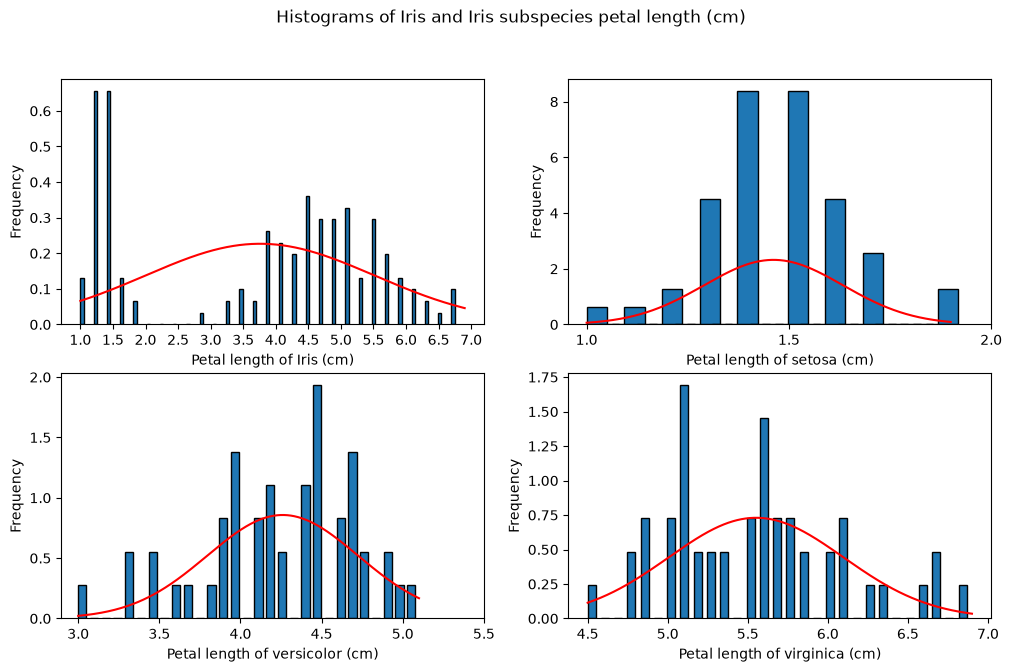

In [66]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 7))

species = [None] + df["species"].unique().tolist()

for ax, specie in zip(axs.flatten(), species):
    draw_hist(ax, specie)
fig.suptitle("Histograms of Iris and Iris subspecies petal length (cm)")

In [71]:
species = [None] + df["species"].unique().tolist()

for specie in species:

    if specie is None:
        data = df["petal length (cm)"]
        specie = "Iris"
    else:
        data = df[df["species"] == specie]["petal length (cm)"]

    # Calculate the mean of the petal length variable.
    mu = np.mean(data)
    # Calculate the standard deviation of the petal length variable.
    sigma = np.std(data)

    print(f'''
    The mean of {specie} petal length: {mu}. 
    The standard deviation of {specie} petal length: {sigma}''')


    The mean of Iris petal length: 3.7580000000000005. 
    The standard deviation of Iris petal length: 1.759404065775303

    The mean of setosa petal length: 1.4620000000000002. 
    The standard deviation of setosa petal length: 0.17191858538273283

    The mean of versicolor petal length: 4.26. 
    The standard deviation of versicolor petal length: 0.4651881339845203

    The mean of virginica petal length: 5.5520000000000005. 
    The standard deviation of virginica petal length: 0.546347874526844


In the above plot, we draw four different histograms. The first histogram shows visual representation of the combined data for all Iris species. The other three histograms are visual representations of each Iris species setosa, versicolor, and virginica. In addition, each histogram has superimposed probability density function of normal distribution based on the mean and standard deviation of the data.

These plots shows the distribution of each data and helps to see if the data is normally distributed. It is important to understand if dataset follows a specific distribution which will dictate what statistical method to choose. If the dataset follows a specific distribution, then a parametric statistical test may be used and if it does not follows any specific distribution, then a non-parametric test may be used ([see source](https://blog.minitab.com/en/blog/adventures-in-statistics-2/choosing-between-a-nonparametric-test-and-a-parametric-test)). For example, if a datset follows a normal distribution, then a t-test for two groups or ANOVA for 3 or more groups may be used to examine the difference between the groups. In contrast, if the data does not follow normal distribution then, the data may be transformed to make it normal or a non-parametric test will be used to test the differences between datasets.

However, in the first plot we can see that the data has two peaks at 1.5 and 4.5. which says that data is mixed and probably comprised of different groups and could not be used to model the petal length of the Iris flower. In addition, the superimposed plot of the probability density function of normal distribution based on the data's mean and standard deviation shows that data has large dispersion because the peak of superimpsed plot is flat. When we draw the other three histograms we can see where those two peaks are coming from. The setosa dataset is clustered around 1.5 and the other two species versicolor and virginica are clustered around 4.5 peak. Furthermore,

The histogram of setosa is visually normally distributed based on the histogram and superimposed plot. Histogram is centered at around 1.5 with two relatively similar tales on the right and left of the center. THe superimposed plot also has a peak with two similar slopes on the both sides of the peak.